In [2]:
print("Helo, Zambia")

Helo, Zambia


In [4]:
import json
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
# ---- House style --------------------------------------------------------
plt.rcParams.update({
"figure.figsize": (9, 4.5),
"figure.dpi": 110,
"figure.facecolor": "#fcfcfb",
"axes.facecolor": "#fcfcfb",
"axes.edgecolor": "#c3c2b7",
"axes.labelcolor": "#52514e",
"axes.titlesize": 13,
"axes.titleweight": "bold",
"axes.titlelocation": "left",
"axes.spines.top": False,
"axes.spines.right": False,
"axes.grid": True,
"axes.grid.axis": "y",
"grid.color": "#e1e0d9",
"grid.linewidth": 0.8,
"xtick.color": "#898781",
"ytick.color": "#898781",
"font.size": 10,
"legend.frameon": False,
"lines.linewidth": 2,
})
# ---- Palette ------------------------------------------------------------
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
GREY, GREY_LIGHT = "#898781", "#d6d5cf"
INK, INK_SOFT = "#0b0b0b", "#52514e"
SERIES = [BLUE, ORANGE, AQUA, YELLOW]
# fixed order, never cycled
print("Matplotlib", plt.matplotlib.__version__, "| pandas", pd.__version__)

Matplotlib 3.11.2 | pandas 3.1.0


In [6]:
with open("zambia_synthetic_climate_2021_2025.json") as f:
  data = json.load(f)
print(data["metadata"]["title"])
print("Period:", data["metadata"]["period"])
print("Sections:", list(data.keys()))
provinces = pd.DataFrame(data["provinces"])
monthly = pd.DataFrame(data["monthly"])
annual = pd.DataFrame(data["annual"])
monthly["date"] = pd.to_datetime(monthly["date"])
print(f"\nmonthly: {monthly.shape}, annual: {annual.shape}, provinces: {provinces.shape}")
monthly.head()

Synthetic Zambia climate, population and air-quality dataset
Period: 2021-01 to 2025-12
Sections: ['metadata', 'provinces', 'monthly', 'annual']

monthly: (600, 14), annual: (50, 7), provinces: (10, 4)


,province,year,month,month_name,date,rainfall_mm,rainy_days,temp_mean_c,temp_max_c,temp_min_c,humidity_pct,pm25_ugm3,so2_ugm3,air_quality_category
0,Central,2021,1,Jan,2021-01-01,232.9,21,21.7,28.0,15.1,73.4,13.0,6.1,Moderate
1,Central,2021,2,Feb,2021-02-01,208.4,17,22.5,30.4,15.0,64.6,11.6,6.3,Good
2,Central,2021,3,Mar,2021-03-01,190.8,18,21.5,29.2,13.8,68.5,12.3,5.4,Moderate
3,Central,2021,4,Apr,2021-04-01,58.9,5,21.8,29.1,15.6,33.5,14.6,6.1,Moderate
4,Central,2021,5,May,2021-05-01,4.7,1,19.3,28.2,12.2,32.5,21.1,5.7,Moderate


In [7]:
annual.head()

,province,year,population,urban_population_pct,total_rainfall_mm,mean_temp_c,mean_pm25_ugm3
0,Central,2021,1945544,27.1,1012.3,21.04,19.6
1,Central,2022,2009197,29.7,1028.8,21.32,19.3
2,Central,2023,2064540,17.6,1001.4,21.48,20.3
3,Central,2024,2134243,23.8,553.8,21.93,22.4
4,Central,2025,2189284,16.9,1046.0,21.51,20.0


PART 3 Build the charts

The pattern behind every chart
1. fig, ax = plt.subplots() creates a Figure (the whole canvas) and an Axes (one plot area on it).
2. A method on ax draws the data: ax.plot, ax.bar, ax.scatter and so on.
3. Further ax.set_... methods add the title, axis labels and limits.
4. plt.show() displays the finished figure.
Calling methods on ax is called the object-oriented style. Older tutorials use plt.plot(...) directly;
it works for one plot but becomes confusing as soon as a figure has several.

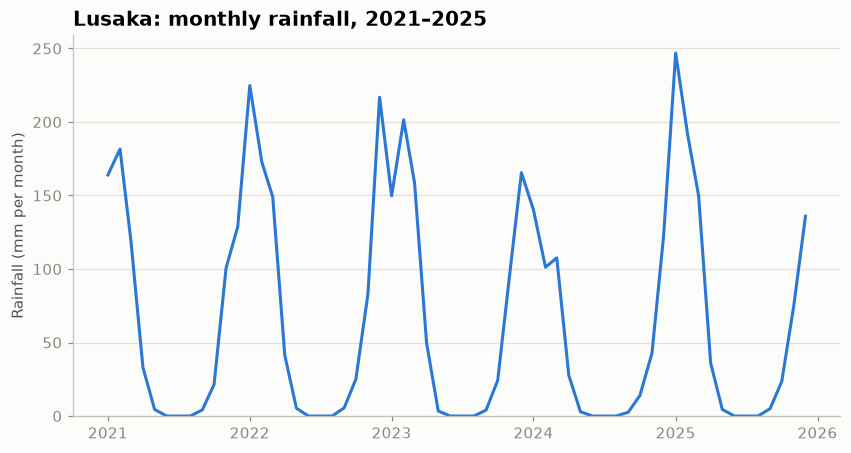

In [8]:
lusaka = monthly[monthly["province"] == "Lusaka"]
fig, ax = plt.subplots()
# 1. create the canvas and one Axes
ax.plot(lusaka["date"], lusaka["rainfall_mm"], color=BLUE)
# 2. draw the data
ax.set_title("Lusaka: monthly rainfall, 2021–2025")
# 3. label it
ax.set_ylabel("Rainfall (mm per month)")
ax.set_ylim(bottom=0)
# rainfall can't be negative; start at zero
plt.show()

This first line plot demonstrates how a time-series graph can be used to visualize monthly rainfall. Rather than looking at many individual rainfall numbers in a table, the line makes the overall pattern immediately visible: Lusaka experiences pronounced wet and dry periods, while the amount of rainfall during the wetter periods varies from year to year.


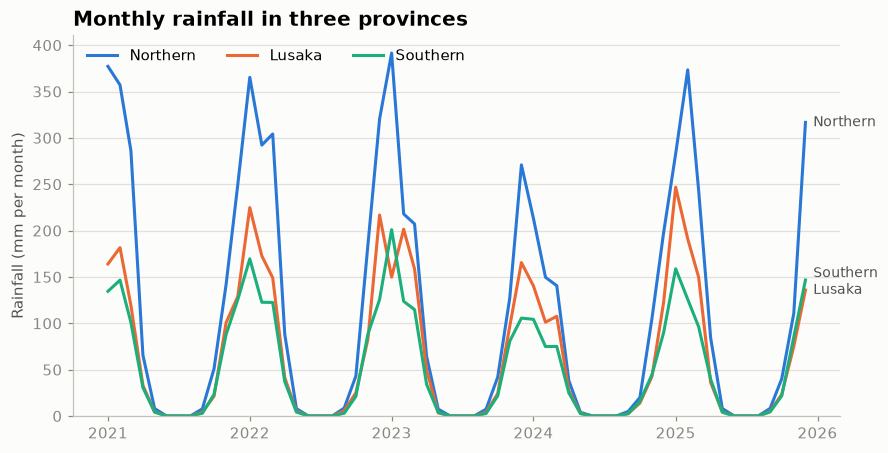

In [11]:
chosen = ["Northern", "Lusaka", "Southern"]
fig, ax = plt.subplots()
ends = []
for name, colour in zip(chosen, SERIES):
  sub = monthly[monthly["province"] == name]
  ax.plot(sub["date"], sub["rainfall_mm"], color=colour, label=name)
  ends.append([sub["rainfall_mm"].iloc[-1], name])
# Direct labels at the right-hand end. Lines can finish close together,
# so push labels apart until they are at least 18 mm apart vertically.
ends.sort()
for i in range(1, len(ends)):
  ends[i][0] = max(ends[i][0], ends[i - 1][0] + 18)
x_label = monthly["date"].max() + pd.Timedelta(days=20)
for y, name in ends:
  ax.text(x_label, y, name, color=INK_SOFT, va="center", fontsize=9)
ax.set_title("Monthly rainfall in three provinces")
ax.set_ylabel("Rainfall (mm per month)")
ax.set_ylim(bottom=0)
ax.legend(loc="upper left", ncols=3)
plt.show()

The graph clearly illustrates the regional differences in rainfall. Northern Province is the wettest of the three; Lusaka generally experiences intermediate rainfall, while Southern Province is generally the driest. At the same time, all three provinces show similar seasonal timing, with rainfall increasing and decreasing at approximately the same periods. The chart therefore provides a useful visual comparison of both rainfall seasonality and geographical variation across the three provinces.


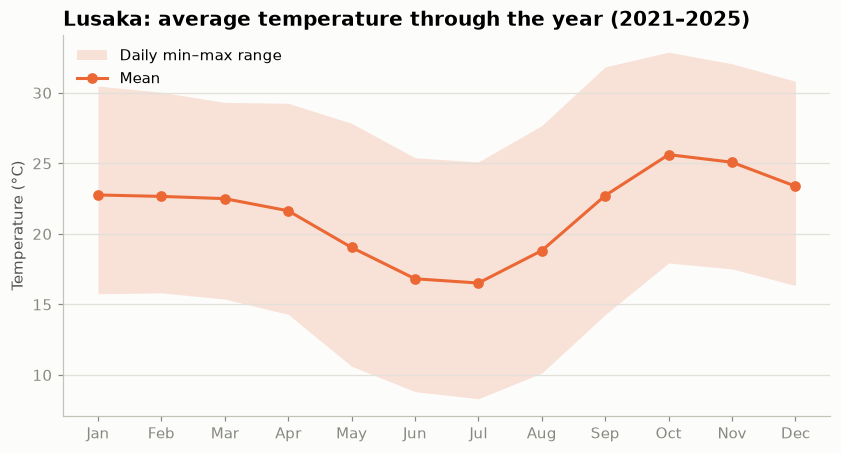

Hottest month: Oct
Coolest month: Jul


In [12]:
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
              "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
lsk_cycle = (monthly[monthly["province"] == "Lusaka"]
            .groupby("month")[["temp_mean_c", "temp_min_c", "temp_max_c"]]
            .mean())
fig, ax = plt.subplots()
ax.fill_between(lsk_cycle.index, lsk_cycle["temp_min_c"], lsk_cycle["temp_max_c"],
            color=ORANGE, alpha=0.18, linewidth=0, label="Daily min–max range")
ax.plot(lsk_cycle.index, lsk_cycle["temp_mean_c"], color=ORANGE,
     marker="o", markersize=6, label="Mean")
ax.set_xticks(range(1, 13), month_names)
ax.set_title("Lusaka: average temperature through the year (2021–2025)")
ax.set_ylabel("Temperature (°C)")
ax.legend(loc="upper left")
plt.show()
print("Hottest month:", month_names[lsk_cycle["temp_mean_c"].idxmax() - 1])
print("Coolest month:", month_names[lsk_cycle["temp_mean_c"].idxmin() - 1])

The graph shows the average tempertaure through the year (2021-2025) in the province of Lusaka. The month of October was the hottest month and July was the coolest month. 

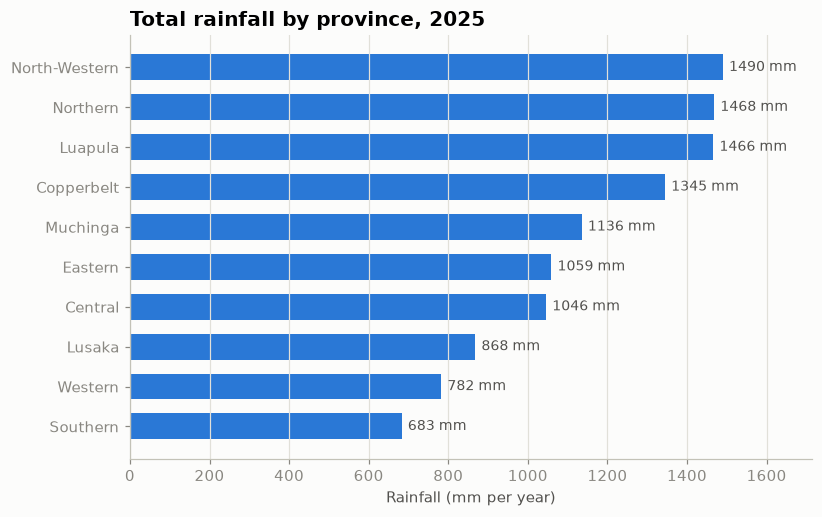

In [13]:
rain_2025 = (annual[annual["year"] == 2025]
            .sort_values("total_rainfall_mm"))
# ascending: largest ends up on top
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(rain_2025["province"], rain_2025["total_rainfall_mm"], color=BLUE, height=0.65)
ax.bar_label(bars, fmt="%.0f mm", padding=4, color=INK_SOFT, fontsize=9)
ax.set_title("Total rainfall by province, 2025")
ax.set_xlabel("Rainfall (mm per year)")
ax.grid(axis="y", visible=False)
# horizontal bars: gridlines on x instead
ax.grid(axis="x", visible=True)
ax.set_xlim(0, rain_2025["total_rainfall_mm"].max() * 1.15)
# room for the labels
plt.show()

The sorted bar chart clearly demonstrates the differences in total rainfall among the provinces in 2025. The highest value, 1,490 mm in North-Western Province, is more than twice the 683 mm recorded for Southern Province. Sorting the bars from highest to lowest makes the ranking immediately visible and allows the provinces with relatively high, moderate, and low annual rainfall totals to be identified easily.

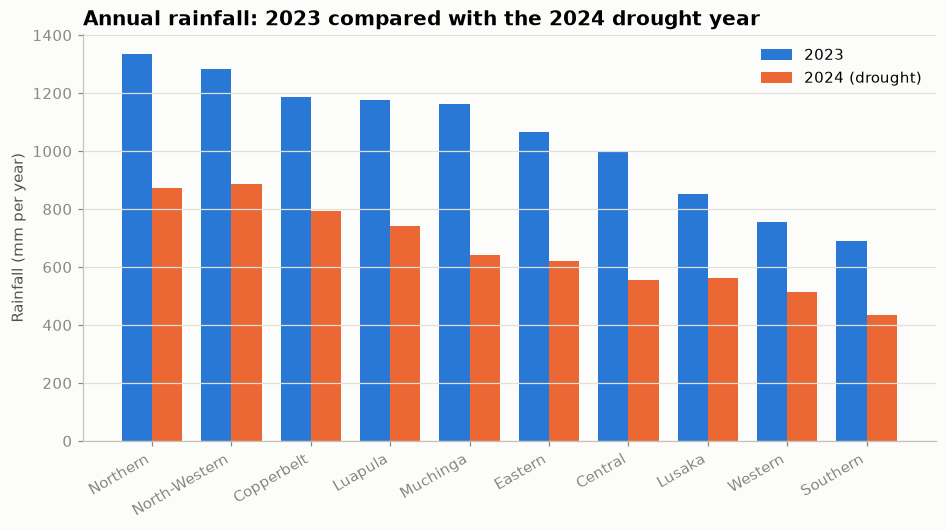

Average fall in rainfall, 2023 → 2024: 37%


In [14]:
wide = (annual[annual["year"].isin([2023, 2024])]
      .pivot(index="province", columns="year", values="total_rainfall_mm")
      .sort_values(2023, ascending=False))
x = np.arange(len(wide))
w = 0.38
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.bar(x - w / 2, wide[2023], width=w, color=BLUE, label="2023")
ax.bar(x + w / 2, wide[2024], width=w, color=ORANGE, label="2024 (drought)")
ax.set_xticks(x, wide.index, rotation=30, ha="right")
ax.set_ylabel("Rainfall (mm per year)")
ax.set_title("Annual rainfall: 2023 compared with the 2024 drought year")
ax.legend(loc="upper right")
plt.show()
drop = (1 - wide[2024] / wide[2023]) * 100
print("Average fall in rainfall, 2023 → 2024:", f"{drop.mean():.0f}%")

The chart indicates an average rainfall reduction of 37% between 2023 and 2024. The consistently shorter orange bars demonstrate that the 2024 drought affected every province, although rainfall levels and the size of the reduction varied by province. The grouped bar chart is therefore effective because it allows direct comparison of the two years while also showing geographical differences in rainfall across the country.

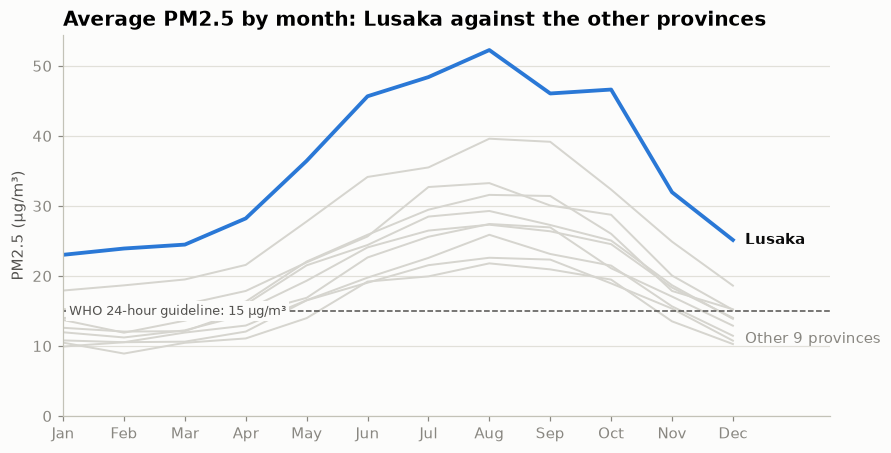

In [60]:
pm_cycle = monthly.groupby(["province", "month"])["pm25_ugm3"].mean().unstack(0)
focus = "Lusaka"
fig, ax = plt.subplots()
for name in pm_cycle.columns:
   if name != focus:
      ax.plot(pm_cycle.index, pm_cycle[name], color=GREY_LIGHT, linewidth=1.3)
ax.plot(pm_cycle.index, pm_cycle[focus], color=BLUE, linewidth=2.5)
ax.text(12.2, pm_cycle[focus].iloc[-1], focus, color=INK, va="center", fontweight="bold")
ax.text(12.2, 11, "Other 9 provinces", color=GREY, va="center")
ax.axhline(15, color=INK_SOFT, linestyle="--", linewidth=1)
# bbox= draws a small background box so the text stays readable over the grey lines
ax.text(1.1, 15, "WHO 24-hour guideline: 15 µg/m³", color=INK_SOFT, fontsize=8.5,
        va="center", bbox=dict(facecolor="#fcfcfb", edgecolor="none", pad=2))
ax.set_xticks(range(1, 13), month_names)
ax.set_xlim(1, 13.6)
ax.set_ylim(bottom=0)
ax.set_title("Average PM2.5 by month: Lusaka against the other provinces")
ax.set_ylabel("PM2.5 (µg/m³)")
plt.show()

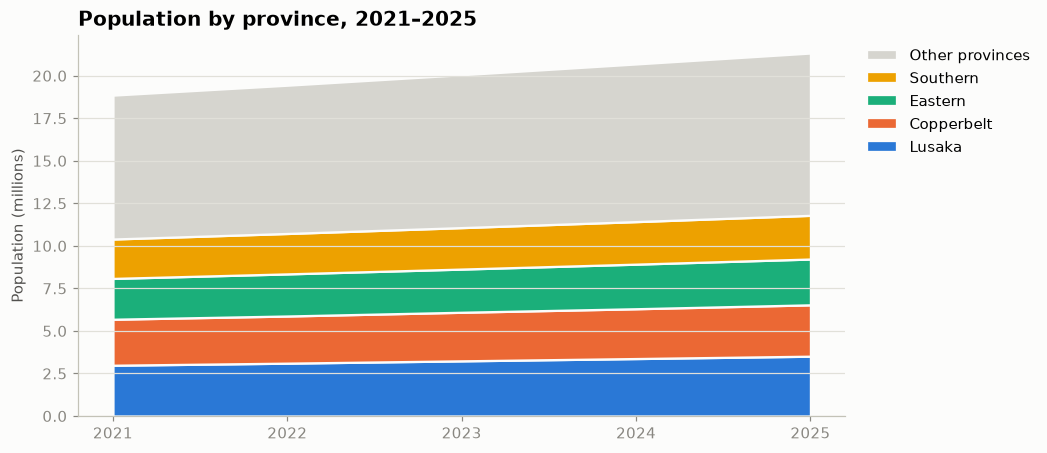

Total population: 18.9 m (2021) → 21.3 m (2025)


In [59]:
pop = annual.pivot(index="year", columns="province", values="population") / 1e6
top4 = pop.iloc[-1].sort_values(ascending=False).index[:4]
pop_plot = pop[top4].copy()
pop_plot["Other provinces"] = pop.drop(columns=top4).sum(axis=1)
fig, ax = plt.subplots()
ax.stackplot(pop_plot.index, pop_plot.T.values, labels=pop_plot.columns,
            colors=SERIES + [GREY_LIGHT], edgecolor="#fcfcfb", linewidth=1.5)
ax.set_xticks(pop_plot.index)
ax.set_ylabel("Population (millions)")
ax.set_title("Population by province, 2021–2025")
# reverse=True lists the legend in the same top-to-bottom order as the bands
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), reverse=True)
plt.show()
total = pop.sum(axis=1)
print(f"Total population: {total.iloc[0]:.1f} m (2021) → {total.iloc[-1]:.1f} m (2025)")

The chart indicates a steady increase in the national population, rising from approximately 18.9 million in 2021 to 21.3 million in 2025. The increasing height of the overall stacked area reflects this growth over the five-year period. Among the provinces highlighted separately, Lusaka, Copperbelt, Eastern and Southern Provinces each contribute a visible share of the total population. The remaining provinces are combined under â€œOther provincesâ€, which collectively account for the largest portion of the national population. The gradual widening of the coloured areas also indicates that the populations represented in the chart increase over the period.

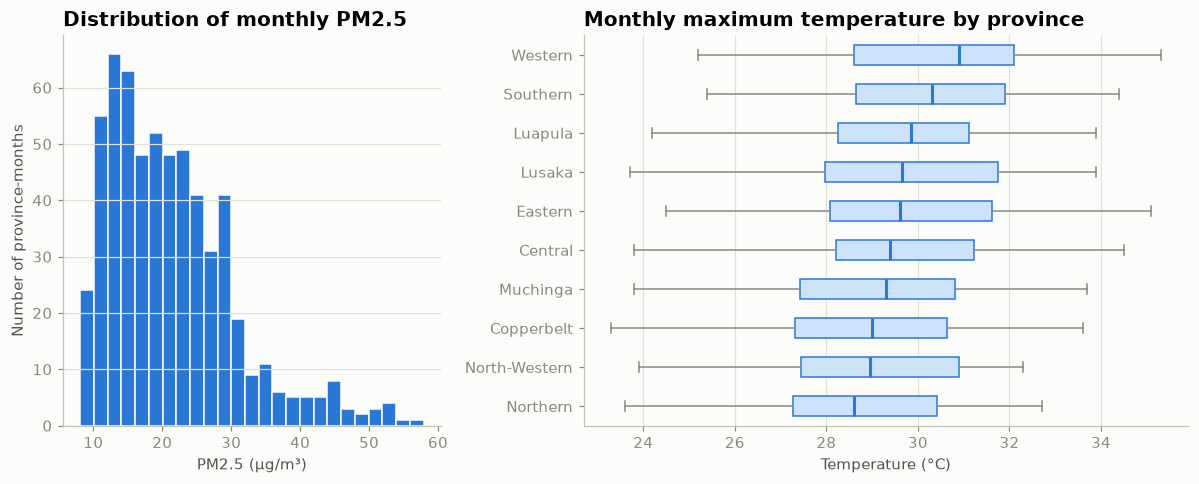

In [20]:
fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(11, 4.5),
    width_ratios=[1, 1.6]
)

# Histogram of all monthly PM2.5 values
ax1.hist(
    monthly["pm25_ugm3"],
    bins=25,
    color=BLUE,
    edgecolor="#fcfcfb"
)

ax1.set_title("Distribution of monthly PM2.5")
ax1.set_xlabel("PM2.5 (µg/m³)")
ax1.set_ylabel("Number of province-months")

# Box plot of maximum temperature, provinces ordered by median
order = (
    monthly.groupby("province")["temp_max_c"]
    .median()
    .sort_values()
    .index
)

groups = [
    monthly.loc[monthly["province"] == p, "temp_max_c"]
    for p in order
]

ax2.boxplot(
    groups,
    tick_labels=order,
    orientation="horizontal",
    patch_artist=True,
    boxprops=dict(
        facecolor="#cde2fb",
        edgecolor=BLUE
    ),
    medianprops=dict(
        color=BLUE,
        linewidth=2
    ),
    whiskerprops=dict(color=GREY),
    capprops=dict(color=GREY),
    flierprops=dict(
        marker="o",
        markersize=4,
        markerfacecolor=GREY,
        markeredgecolor="none"
    )
)

ax2.set_title("Monthly maximum temperature by province")
ax2.set_xlabel("Temperature (°C)")

ax2.grid(axis="y", visible=False)
ax2.grid(axis="x", visible=True)

fig.tight_layout()
plt.show()

The histogram on the left shows the frequency distribution of monthly PM2.5 concentrations. Most observations are concentrated at the lower end of the distribution, particularly between approximately 10 and 30 µg/m³. The highest frequencies occur around the mid-teens. As PM2.5 concentration increases beyond approximately 30 µg/m³, the number of observations generally decreases. A relatively small number of observations extend beyond 40 µg/m³, reaching approximately 55 µg/m³. This indicates that lower to moderate PM2.5 concentrations occur more frequently, while very high concentrations are less common.

The box plots on the right compare the distribution of monthly maximum temperatures across Western, Southern, Luapula, Lusaka, Eastern, Central, Muchinga, Copperbelt, Northwestern, and Northern provinces. The horizontal axis represents temperature in degrees Celsius (Â°C). The boxes show the central range of temperatures for each province, the vertical line within each box represents the median, and the whiskers indicate the broader range of observed values.

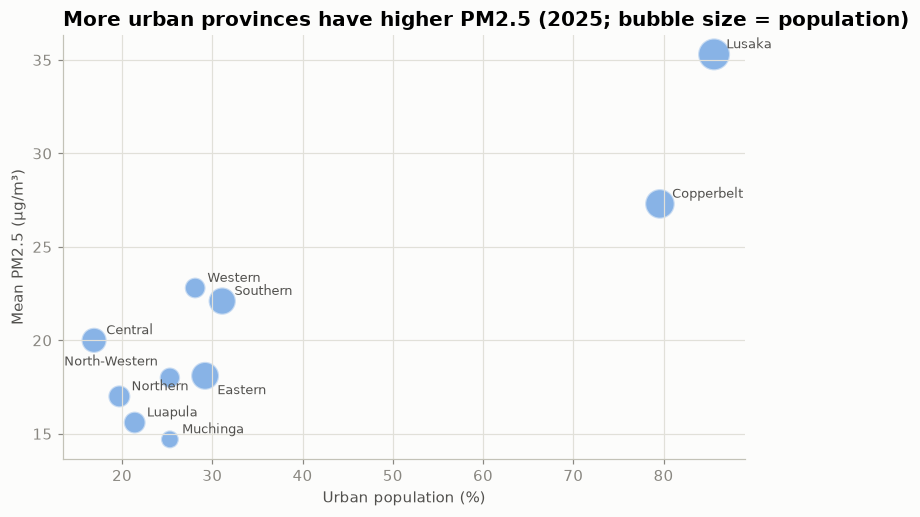

In [61]:
a25 = annual[annual["year"] == 2025]
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(a25["urban_population_pct"], a25["mean_pm25_ugm3"],
          s=a25["population"] / 8000,  # bubble area ∝ population
          color=BLUE, alpha=0.55, edgecolor="#fcfcfb", linewidth=1.5)
nudge = {"Eastern": (8, -12), "North-Western": (-8, 8)}
# move labels that would collide
for _, row in a25.iterrows():
   dx, dy = nudge.get(row["province"], (8, 4))
   ax.annotate(row["province"], (row["urban_population_pct"], row["mean_pm25_ugm3"]),
              xytext=(dx, dy), textcoords="offset points", fontsize=8.5, color=INK_SOFT,
              ha="right" if dx < 0 else "left")
ax.set_xlabel("Urban population (%)")
ax.set_ylabel("Mean PM2.5 (µg/m³)")
ax.set_title("More urban provinces have higher PM2.5 (2025; bubble size = population)")
ax.grid(axis="x", visible=True)
plt.show()

The figure suggests a positive association between urbanization and PM2.5 concentrations in the data presented: provinces with higher proportions of urban population tend to have higher average PM2.5 levels. However, the graph demonstrates an association rather than proving that urbanization directly causes higher PM2.5 concentrations. The use of bubble size provides an additional dimension by showing the relative population sizes of the provinces alongside urbanization and air-quality levels.

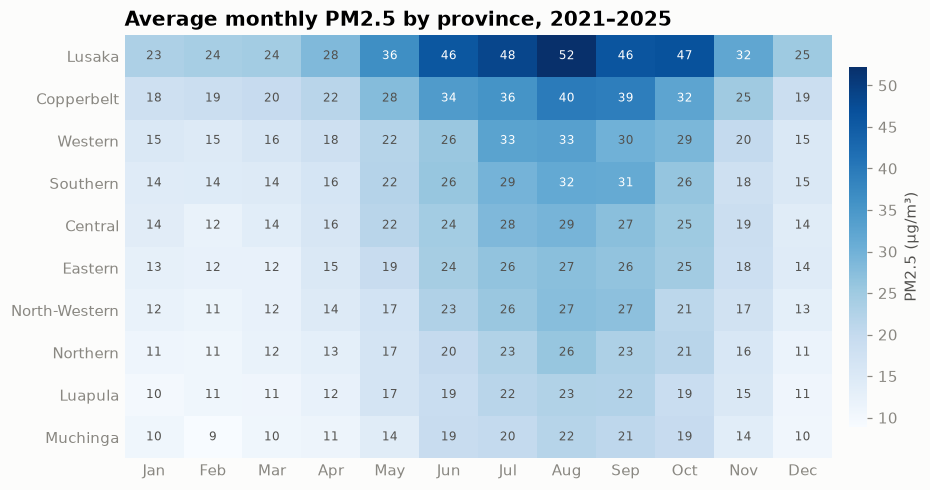

In [22]:
heat = (monthly.groupby(["province", "month"])["pm25_ugm3"].mean()
       .unstack("month"))
heat = heat.loc[heat.mean(axis=1).sort_values(ascending=False).index]

# most polluted on top
fig, ax = plt.subplots(figsize=(10, 5))
im = ax.imshow(heat.values, cmap="Blues", aspect="auto")

ax.set_xticks(range(12), month_names)
ax.set_yticks(range(len(heat)), heat.index)
ax.grid(False)
ax.spines[:].set_visible(False)
ax.tick_params(length=0)

# Write each value in its cell; use white text on dark cells
threshold = heat.values.max() * 0.6
for i in range(heat.shape[0]):
   for j in range(heat.shape[1]):
      v = heat.values[i, j]
      ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8,
             color="white" if v > threshold else INK_SOFT)

cbar = fig.colorbar(im, ax=ax, shrink=0.85, pad=0.02)
cbar.set_label("PM2.5 (µg/m³)")
cbar.outline.set_visible(False)
ax.set_title("Average monthly PM2.5 by province, 2021–2025")
plt.show()

The figure shows a clear seasonal pattern in PM2.5 concentrations across all provinces. Concentrations are generally lower between November and April, begin to increase around May and June, and reach their highest levels mainly between July and October. This pattern is particularly pronounced in Lusaka, where PM2.5 rises from 23 µg/m³ in January to 46 µg/m³ in June, reaches a maximum of 52 µg/m³ in August, and then declines to 25 µg/m³ in December.
Lusaka records the highest PM2.5 concentrations among the provinces throughout the year, followed generally by Copperbelt and Western provinces. For example, in August, the values are 52 µg/m³ for Lusaka, 40 µg/m³ for Copperbelt, and 33 µg/m³ for Western Province. In contrast, provinces such as Luapula and Muchinga display comparatively lower concentrations. Muchinga, for example, ranges from 9 µg/m³ in January to a maximum of 22 µg/m³ during July to September.

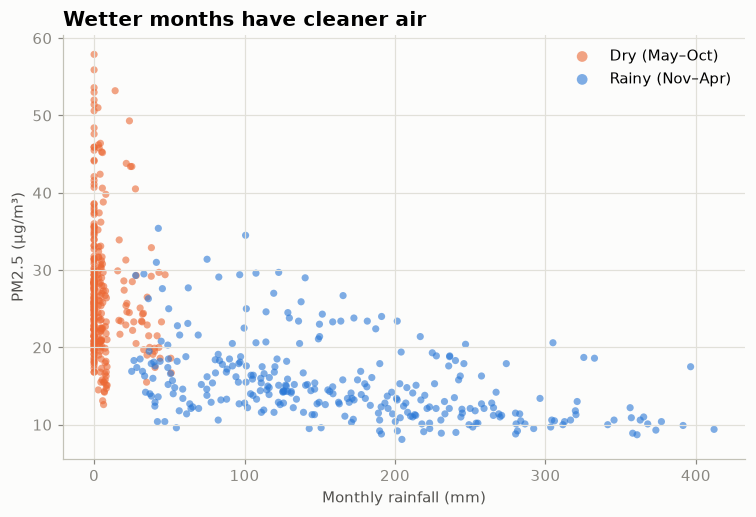

Correlation between rainfall and PM2.5: r = -0.61


In [55]:
rainy_months = [11, 12, 1, 2, 3, 4]
monthly["season"] = np.where(monthly["month"].isin(rainy_months),
                     "Rainy (Nov–Apr)", "Dry (May–Oct)")
fig, ax = plt.subplots(figsize=(8, 5))
for season, colour in [("Dry (May–Oct)", ORANGE), ("Rainy (Nov–Apr)", BLUE)]:
    sub = monthly[monthly["season"] == season]
    ax.scatter(sub["rainfall_mm"], sub["pm25_ugm3"], s=22, color=colour, alpha=0.6,
             edgecolor="none", label=season)
ax.set_xlabel("Monthly rainfall (mm)")
ax.set_ylabel("PM2.5 (µg/m³)")
ax.set_title("Wetter months have cleaner air")
ax.grid(axis="x", visible=True)
ax.legend(loc="upper right", markerscale=1.5)
plt.show()
r = monthly["rainfall_mm"].corr(monthly["pm25_ugm3"])
print(f"Correlation between rainfall and PM2.5: r = {r:.2f}")

The graph shows a clear negative relationship between rainfall and PM2.5 concentration. During the dry season, when rainfall is low or absent, PM2.5 concentrations are generally higher and more variable, with some observations exceeding 50 µg/m³. In contrast, during the rainy season, higher rainfall is generally associated with lower PM2.5 concentrations. At rainfall levels above approximately 200 mm per month, most PM2.5 observations are below about 20 µg/m³.

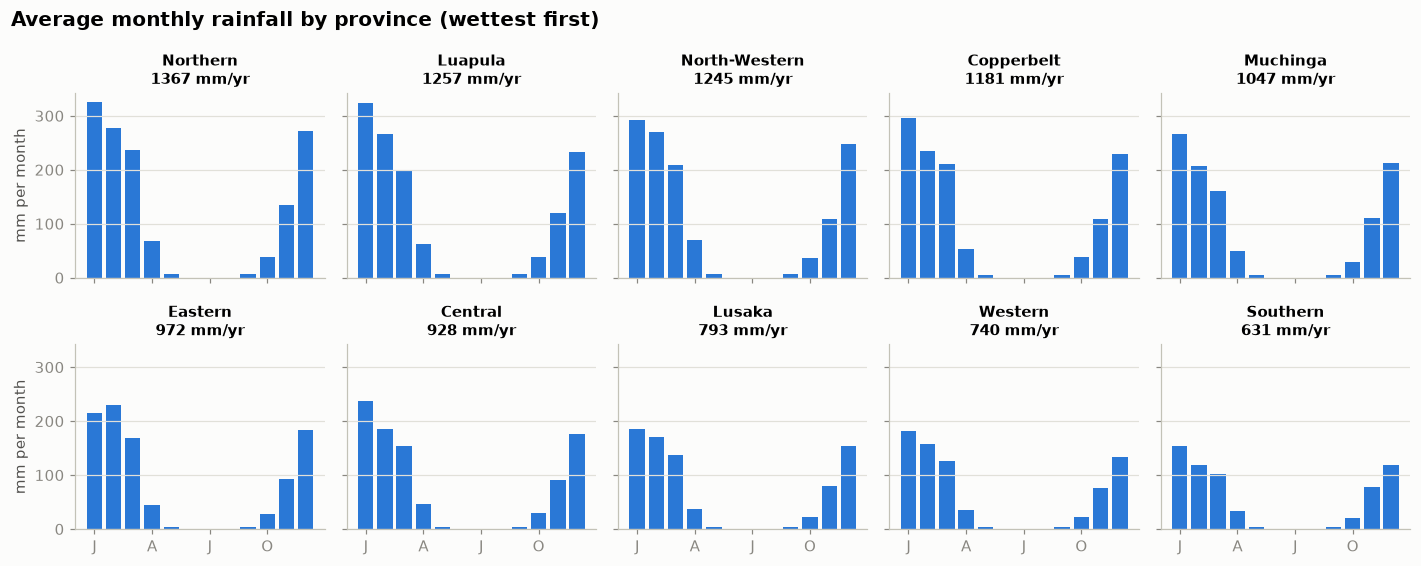

In [56]:
rain_cycle = monthly.groupby(["province", "month"])["rainfall_mm"].mean().unstack(0)
order = rain_cycle.sum().sort_values(ascending=False).index # wettest first

fig, axes = plt.subplots(2, 5, figsize=(13, 5.2), sharex=True, sharey=True)
for ax, name in zip(axes.flat, order):
    ax.bar(rain_cycle.index, rain_cycle[name], color=BLUE, width=0.8)
    ax.set_title(f"{name}\n{rain_cycle[name].sum():.0f} mm/yr", fontsize=10, loc="center")
    ax.set_xticks([1, 4, 7, 10], ["J", "A", "J", "O"])

for ax in axes[:, 0]:
    ax.set_ylabel("mm per month")

fig.suptitle("Average monthly rainfall by province (wettest first)", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

The figure clearly demonstrates the spatial and seasonal variation in rainfall. The northern parts represented by Northern, Luapula, and North-Western Provinces receive substantially more annual rainfall, while Lusaka, Western, and particularly Southern Province receive lower totals. Arranging the provinces from wettest to driest makes these geographical differences easy to identify while also allowing the monthly rainfall pattern within each province to be examined.

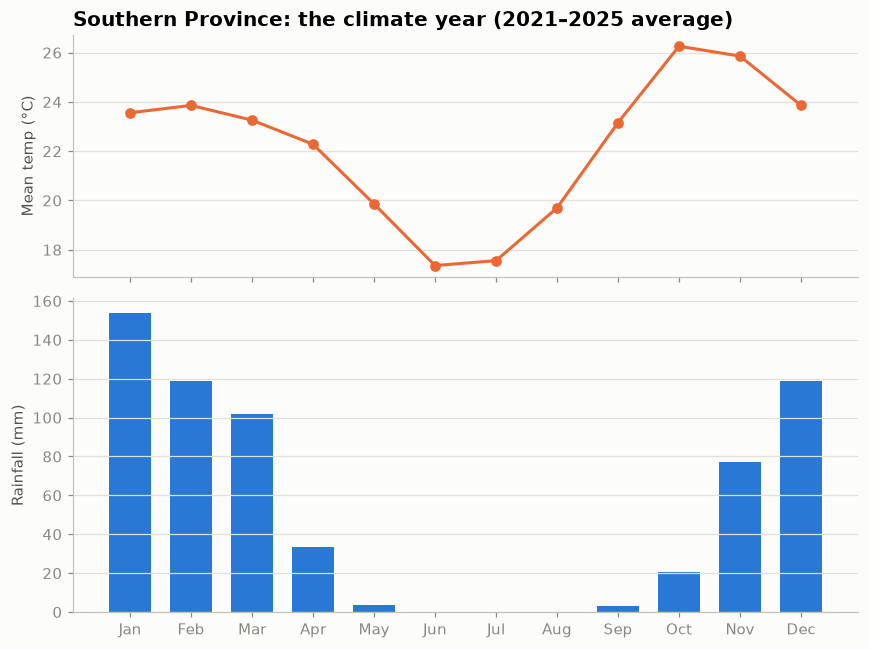

In [27]:
region = "Southern"
cyc = (monthly[monthly["province"] == region]
      .groupby("month")[["rainfall_mm", "temp_mean_c"]]
      .mean())
fig, (ax_t, ax_r) = plt.subplots(2, 1, figsize=(8, 6), sharex=True,
                                height_ratios=[1, 1.3])
ax_t.plot(cyc.index, cyc["temp_mean_c"], color=ORANGE, marker="o")
ax_t.set_ylabel("Mean temp (°C)")
ax_t.set_title(f"{region} Province: the climate year (2021–2025 average)")

ax_r.bar(cyc.index, cyc["rainfall_mm"], color=BLUE, width=0.7)
ax_r.set_ylabel("Rainfall (mm)")
ax_r.set_xticks(range(1, 13), month_names)

fig.tight_layout()
plt.show()

The figure illustrates the average monthly temperature and rainfall pattern for Southern Province based on the 2021â€“2025 average. Rather than presenting temperature and rainfall on a single graph with two y-axes, the variables are displayed in two vertically aligned panels sharing the same monthly time scale. The upper panel shows that temperatures decline from approximately 24Â°C at the beginning of the year to their lowest level of about 17Â°C in June, before increasing to a peak of approximately 26Â°C in October. The lower panel demonstrates a strongly seasonal rainfall pattern, with relatively high rainfall from December to March and very low rainfall during the middle of the year. Together, the panels clearly demonstrate the seasonal relationship between temperature and rainfall while keeping the different measurement units and scales visually distinct.


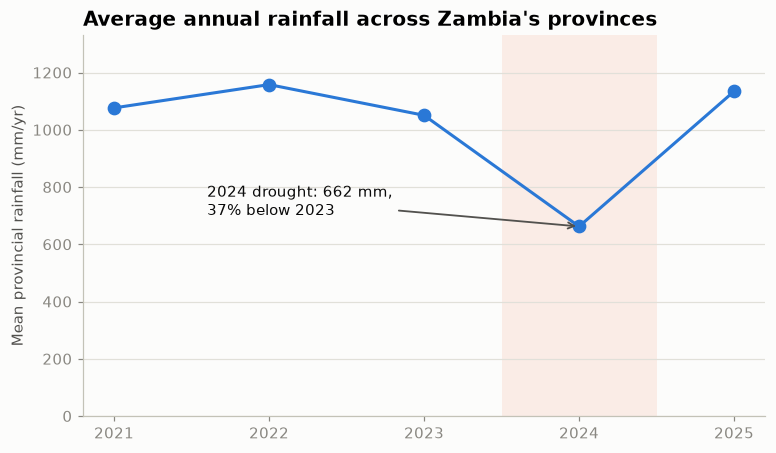

In [28]:
national = annual.groupby("year")["total_rainfall_mm"].mean()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(national.index, national.values, color=BLUE, marker="o", markersize=8)
ax.axvspan(2023.5, 2024.5, color=ORANGE, alpha=0.10, linewidth=0)
ax.annotate(f"2024 drought: {national[2024]:.0f} mm,\n"
          f"{(1 - national[2024] / national[2023]) * 100:.0f}% below 2023",
          xy=(2024, national[2024]), xytext=(2021.6, national[2024] + 40),
          arrowprops=dict(arrowstyle="->", color=INK_SOFT, linewidth=1.2),
          fontsize=10, color=INK)

ax.set_xticks(national.index)
ax.set_ylim(0, national.max() * 1.15)
ax.set_ylabel("Mean provincial rainfall (mm/yr)")
ax.set_title("Average annual rainfall across Zambia's provinces")
plt.show()

The figure draws particular attention to the 2024 drought by highlighting the substantial decline in average annual rainfall. Rainfall decreased from approximately 1,050 mm in 2023 to 662 mm in 2024, representing a 37% reduction according to the graph. The shaded area, arrow and annotation emphasize 2024 as an exceptional low-rainfall year compared with the surrounding years. The subsequent increase in 2025 further emphasizes the unusually low rainfall recorded in 2024.


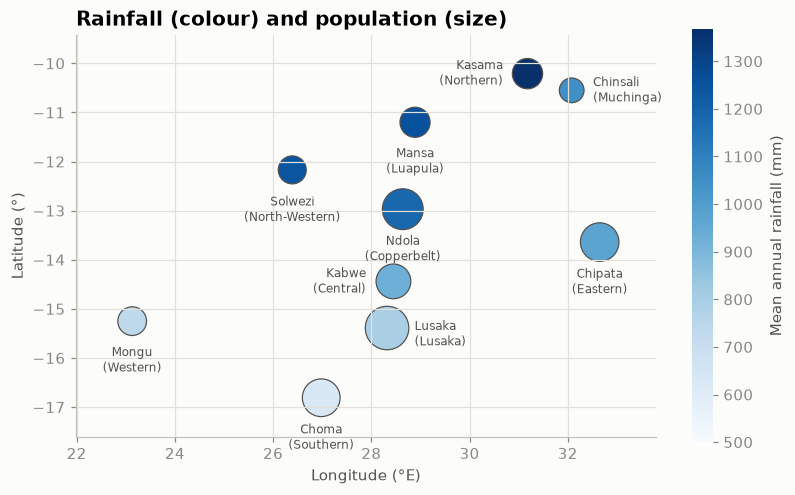

In [29]:
geo = provinces.merge(
     annual.groupby("province", as_index=False)[["total_rainfall_mm", "population"]].mean(),
     on="province")

fig, ax = plt.subplots(figsize=(8.5, 6.5))
sc = ax.scatter(geo["longitude"], geo["latitude"], c=geo["total_rainfall_mm"], cmap="Blues",
               s=geo["population"] / 4000, vmin=500, edgecolor=INK_SOFT, linewidth=0.8)

# Default: label below the circle. Some capitals sit close together, so place
# those labels to one side instead (offset in points, horizontal alignment).
place = {"Kasama": ((-16, 0), "right"), "Chinsali": ((14, 0), "left"),
         "Kabwe": ((-18, 0), "right"), "Lusaka": ((18, -4), "left")}
for _, row in geo.iterrows():
   (dx, dy), ha = place.get(row["capital"], ((0, -16), "center"))
   ax.annotate(f"{row['capital']}\n({row['province']})", (row["longitude"], row["latitude"]),
            xytext=(dx, dy), textcoords="offset points", ha=ha,
            va="top" if dy < -10 else "center", fontsize=8, color=INK_SOFT)

cbar = fig.colorbar(sc, ax=ax, shrink=0.75)
cbar.set_label("Mean annual rainfall (mm)")
cbar.outline.set_visible(False)
ax.set_aspect("equal")

# one degree east = one degree north
ax.set_xlabel("Longitude (°E)")
ax.set_ylabel("Latitude (°)")
ax.grid(axis="x", visible=True)
ax.margins(0.12)
ax.set_title("Rainfall (colour) and population (size)")
plt.show()


The figure presents the approximate geographical distribution of Zambia's provincial capitals using longitude and latitude coordinates. Mean annual rainfall is represented by the colour of each point, with darker blue indicating higher rainfall and lighter blue indicating lower rainfall, while the size of each point represents population. A general northâ€“south rainfall gradient is visible. Northern locations such as Kasama, Mansa and Solwezi are associated with relatively higher rainfall, whereas southern locations, particularly Choma, are associated with lower rainfall. The figure therefore provides a simple visual demonstration of the spatial variation in rainfall across the country while simultaneously showing differences in the population sizes of the provincial capitals.


**SAVE YOUR FIGURES TO FILES**
Goal: export a chart for a report or slide.

In [30]:
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(rain_2025["province"], rain_2025["total_rainfall_mm"], color=BLUE, height=0.65)
ax.bar_label(bars, fmt="%.0f", padding=4, color=INK_SOFT, fontsize=9)
ax.set_title("Total rainfall by province, 2025 (synthetic data)")
ax.set_xlabel("Rainfall (mm per year)")
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)

fig.savefig("rainfall_2025.png", dpi=200, bbox_inches="tight")
fig.savefig("rainfall_2025.pdf", bbox_inches="tight")
plt.close(fig)

# close it so it isn't also displayed below
import os
for name in ["rainfall_2025.png", "rainfall_2025.pdf"]:
   print(f"{name}: {os.path.getsize(name) / 1024:.0f} KB")

rainfall_2025.png: 72 KB
rainfall_2025.pdf: 25 KB


**PART 4 PRACTICE AND CHECK YOUR WORK**

**Line Plot (Steps 10-11: monthly mean temperature (temp_mean_c) for Copperbelt,
Lusaka and Western on one chart with direct labels. Which province is warmest in October?**

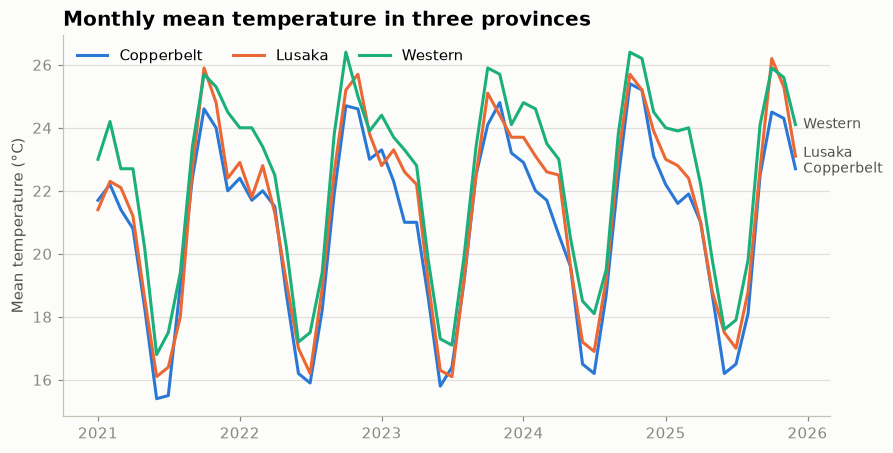

In [41]:
import matplotlib.pyplot as plt

chosen = ["Copperbelt", "Lusaka", "Western"]

fig, ax = plt.subplots()

ends = []

for name, colour in zip(chosen, SERIES):
    sub = monthly[monthly["province"] == name]

    ax.plot(
        sub["date"],
        sub["temp_mean_c"],
        color=colour,
        label=name
    )

    ends.append([sub["temp_mean_c"].iloc[-1], name])

# Direct labels at the right-hand end
ends.sort()

for i in range(1, len(ends)):
    ends[i][0] = max(ends[i][0], ends[i - 1][0] + 0.5)

x_label = monthly["date"].max() + pd.Timedelta(days=20)

for y, name in ends:
    ax.text(
        x_label,
        y,
        name,
        color=INK_SOFT,
        va="center",
        fontsize=9
    )

ax.set_title("Monthly mean temperature in three provinces")
ax.set_ylabel("Mean temperature (°C)")
ax.legend(loc="upper left", ncols=3)

plt.show()

The line graph shows a strong seasonal pattern in monthly mean temperatures across Copperbelt, Lusaka, and Western Provinces. Temperatures generally decline during the cooler middle months of each year before increasing sharply toward the hotter months. Western Province generally records the highest mean temperatures, while Copperbelt tends to record the lowest. In October, Western Province is the warmest of the three provinces, indicating consistently higher temperatures during this part of the year.



**Sorted Bars showing Population Growth from 2021 to 2025 as a percentage**

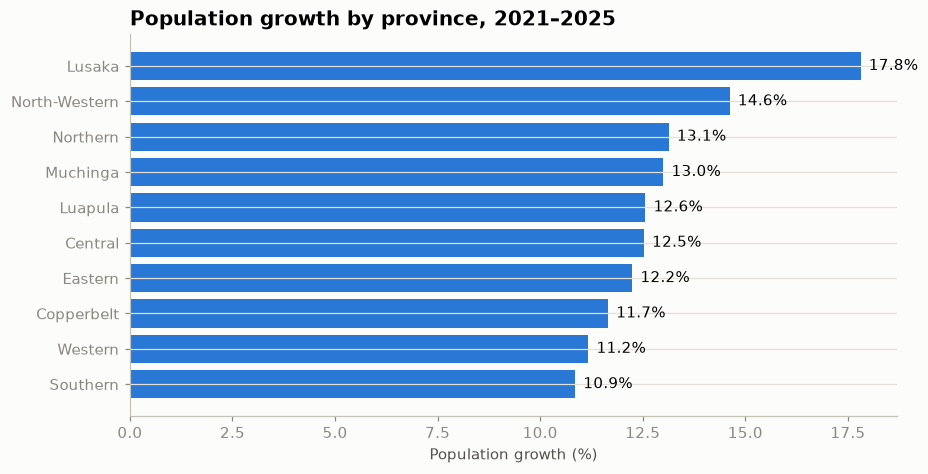

In [35]:
pop_2021 = annual[annual["year"] == 2021][
    ["province", "population"]
].rename(columns={"population": "pop_2021"})

pop_2025 = annual[annual["year"] == 2025][
    ["province", "population"]
].rename(columns={"population": "pop_2025"})

growth = pop_2021.merge(pop_2025, on="province")

growth["growth_pct"] = (
    (growth["pop_2025"] - growth["pop_2021"])
    / growth["pop_2021"]
    * 100
)

growth = growth.sort_values("growth_pct")

fig, ax = plt.subplots()

ax.barh(
    growth["province"],
    growth["growth_pct"],
    color=BLUE
)

ax.set_title("Population growth by province, 2021–2025")
ax.set_xlabel("Population growth (%)")

for i, value in enumerate(growth["growth_pct"]):
    ax.text(
        value + 0.2,
        i,
        f"{value:.1f}%",
        va="center"
    )

plt.show()

The sorted horizontal bar chart shows that Lusaka Province experienced the fastest population growth between 2021 and 2025, at approximately 17%. North-Western Province recorded the second-highest growth at 14.6%, followed by Northern Province at 13.1% and Muchinga Province at 13.0%. In contrast, Southern Province had the lowest population growth at 10.9%. Overall, all provinces recorded positive population growth over the period, although the rate of growth varied across provinces.

3. **Calculate yearly average SO₂**

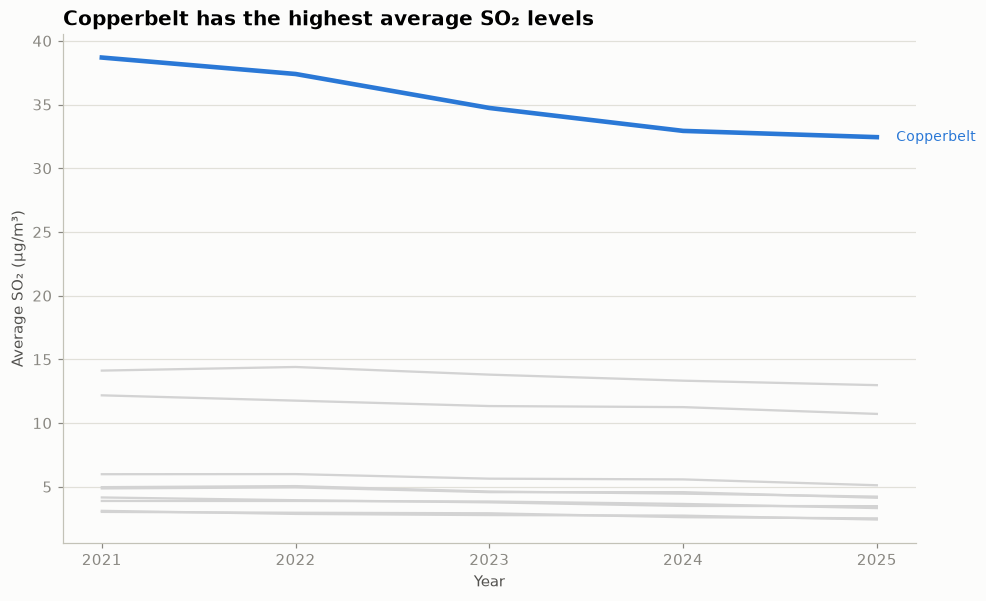

In [53]:
# Question 3: Highlight yearly average SO2
# All provinces are grey; Copperbelt is highlighted

import matplotlib.pyplot as plt

# Calculate yearly average SO2 for each province
yearly_so2 = (
    monthly
    .groupby(["province", "year"], as_index=False)["so2_ugm3"]
    .mean()
)

fig, ax = plt.subplots(figsize=(10, 6))

# Plot every province in grey
for name in yearly_so2["province"].unique():
    sub = yearly_so2[yearly_so2["province"] == name]

    ax.plot(
        sub["year"],
        sub["so2_ugm3"],
        color="lightgrey",
        linewidth=1.5
    )

# Highlight Copperbelt in colour
copperbelt = yearly_so2[
    yearly_so2["province"] == "Copperbelt"
]

ax.plot(
    copperbelt["year"],
    copperbelt["so2_ugm3"],
    color=BLUE,
    linewidth=3
)

# Direct label for Copperbelt
ax.text(
    copperbelt["year"].iloc[-1] + 0.1,
    copperbelt["so2_ugm3"].iloc[-1],
    "Copperbelt",
    color=BLUE,
    va="center",
    fontsize=9
)

# Finding-based title
ax.set_title("Copperbelt has the highest average SO₂ levels")

ax.set_xlabel("Year")
ax.set_ylabel("Average SO₂ (µg/m³)")
ax.set_xticks(yearly_so2["year"].unique())

plt.show()

The figures show that Copperbelt Province recorded the highest average SO₂ concentrations in every year from 2021 to 2025. Although average SO₂ declined from approximately 39 µg/m³ in 2021 to about 33 µg/m³ in 2025, the province remained well above all other provinces throughout the study period. The highlighted line therefore shows both a gradual reduction in Copperbelt’s SO₂ levels and a persistent provincial disparity in air pollution.

**Question 4: Province × year heatmap of total rainfall**

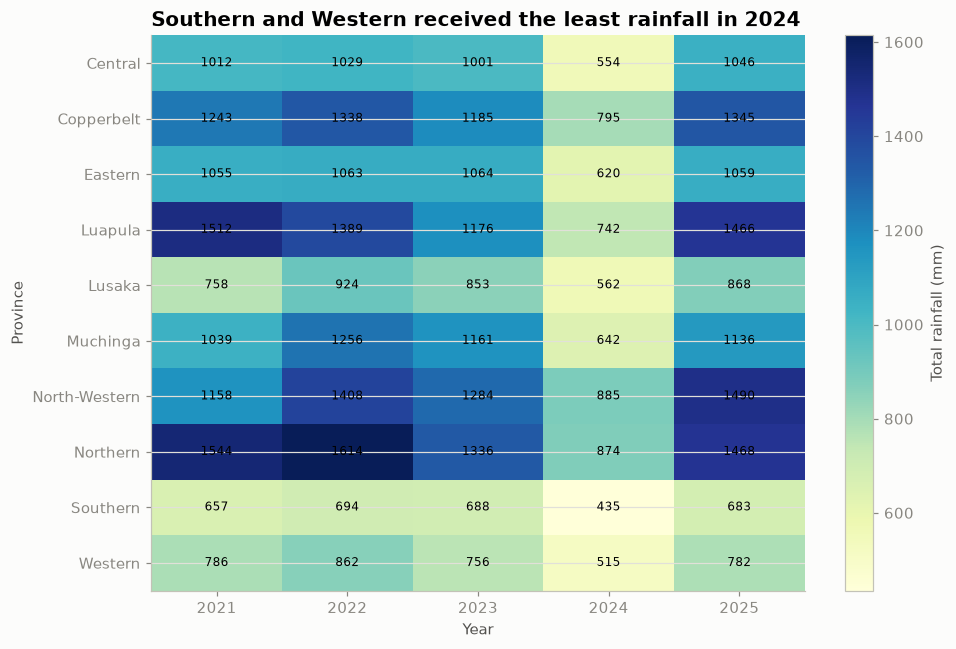

         province  year  rainfall_mm
43       Southern  2024        434.8
48        Western  2024        514.8
3         Central  2024        553.8
23         Lusaka  2024        561.6
13        Eastern  2024        619.9
28       Muchinga  2024        642.5
18        Luapula  2024        741.8
8      Copperbelt  2024        794.6
38       Northern  2024        873.6
33  North-Western  2024        885.2


In [48]:
# Question 4: Province × year heatmap of total rainfall

import matplotlib.pyplot as plt

# Calculate total rainfall for each province in each year
yearly_rainfall = (
    monthly
    .groupby(["province", "year"], as_index=False)["rainfall_mm"]
    .sum()
)

# Reshape the data: provinces = rows, years = columns
rainfall_heatmap = yearly_rainfall.pivot(
    index="province",
    columns="year",
    values="rainfall_mm"
)

# Create the heatmap
fig, ax = plt.subplots(figsize=(9, 6))

heatmap = ax.imshow(
    rainfall_heatmap.values,
    cmap="YlGnBu",
    aspect="auto"
)

# Set year labels on x-axis
ax.set_xticks(range(len(rainfall_heatmap.columns)))
ax.set_xticklabels(rainfall_heatmap.columns)

# Set province labels on y-axis
ax.set_yticks(range(len(rainfall_heatmap.index)))
ax.set_yticklabels(rainfall_heatmap.index)

# Add rainfall values inside the heatmap cells
for i in range(len(rainfall_heatmap.index)):
    for j in range(len(rainfall_heatmap.columns)):
        value = rainfall_heatmap.iloc[i, j]

        ax.text(
            j,
            i,
            f"{value:.0f}",
            ha="center",
            va="center",
            fontsize=8
        )

# Add colour bar
cbar = fig.colorbar(heatmap, ax=ax)
cbar.set_label("Total rainfall (mm)")

# Labels and finding-based title
ax.set_title("Southern and Western received the least rainfall in 2024")
ax.set_xlabel("Year")
ax.set_ylabel("Province")

plt.tight_layout()
plt.show()

# Find the provinces hardest hit in 2024
rainfall_2024 = (
    yearly_rainfall[yearly_rainfall["year"] == 2024]
    .sort_values("rainfall_mm")
)

print(rainfall_2024)

The heatmap shows that the Southern and Western Provinces were hit hardest in 2024, recording the lowest total rainfall of approximately 434.8 mm and 514.8 mm, respectively. Southern Province was the most severely affected, followed by Western Province. Central and Lusaka Provinces also recorded comparatively low rainfall totals.


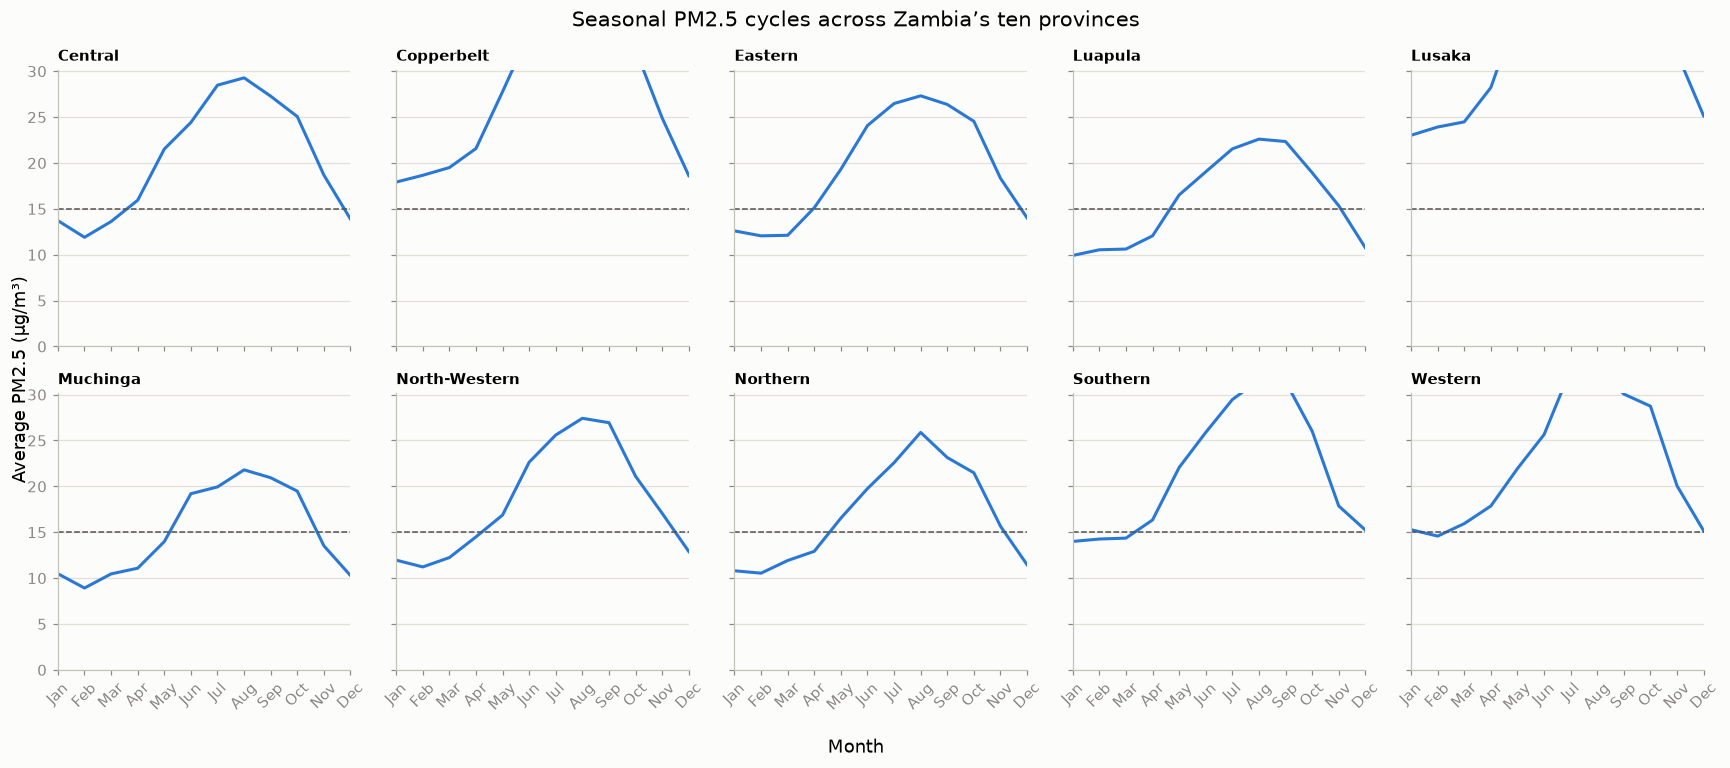

In [50]:
# Question 5: Small multiples of PM2.5 seasonal cycles

import matplotlib.pyplot as plt

# Calculate average monthly PM2.5 for each province
pm_cycle = (
    monthly
    .groupby(["province", "month"])["pm25_ugm3"]
    .mean()
    .unstack(0)
)

# Month labels
month_names = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

# Create a 2 × 5 grid
fig, axes = plt.subplots(
    2,
    5,
    figsize=(16, 7),
    sharex=True,
    sharey=True
)

# Convert the grid of axes into one sequence
axes = axes.flatten()

# Draw one province in each panel
for ax, name in zip(axes, pm_cycle.columns):

    ax.plot(
        pm_cycle.index,
        pm_cycle[name],
        color=BLUE,
        linewidth=2
    )

    # Add the WHO guideline used in Step 15
    ax.axhline(
        15,
        color=INK_SOFT,
        linestyle="--",
        linewidth=1
    )

    ax.set_title(name, fontsize=10)
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(month_names, rotation=45)
    ax.set_xlim(1, 12)
    ax.set_ylim(bottom=0)

# Overall title and shared axis labels
fig.suptitle(
    "Seasonal PM2.5 cycles across Zambia’s ten provinces",
    fontsize=14
)

fig.supxlabel("Month")
fig.supylabel("Average PM2.5 (µg/m³)")

plt.tight_layout()
plt.show()

The 2 × 5 small-multiples chart is better than the Step 15 highlighted chart when the objective is to examine the seasonal PM2.5 cycle of every province separately. It avoids overlapping lines and gives each province equal visual attention, making it easier to identify the timing and shape of seasonal changes in all ten provinces. However, it is worse when the main objective is to emphasise Lusaka or compare Lusaka directly with the other provinces. In that case, the Step 15 chart is more effective because Lusaka is highlighted in colour within a shared plotting area while the other nine provinces provide immediate background context.

**6. Three problems with the classmate's chart**

a). Too many bright colours: Ten brightly coloured provincial rainfall lines create visual clutter.It becomes difficult to follow an individual province and distinguish all ten colours reliably.

b). Too many overlapping lines: Monthly rainfall varies considerably, so placing all ten provinces on one chart creates a “spaghetti plot”.
Provincial seasonal patterns can become hidden by overlapping lines.

c). ax.twinx() makes interpretation difficult: Rainfall and temperature have different units and scales. Putting them on separate y-axes in the same panel can make unrelated movements appear visually comparable.
The interpretation can also change depending on the limits chosen for the two axes.


Redesign

A clearer solution is to use two vertically stacked plots with the same x-axis: rainfall above and temperature below. Use small multiples for the ten provinces rather than ten bright lines.

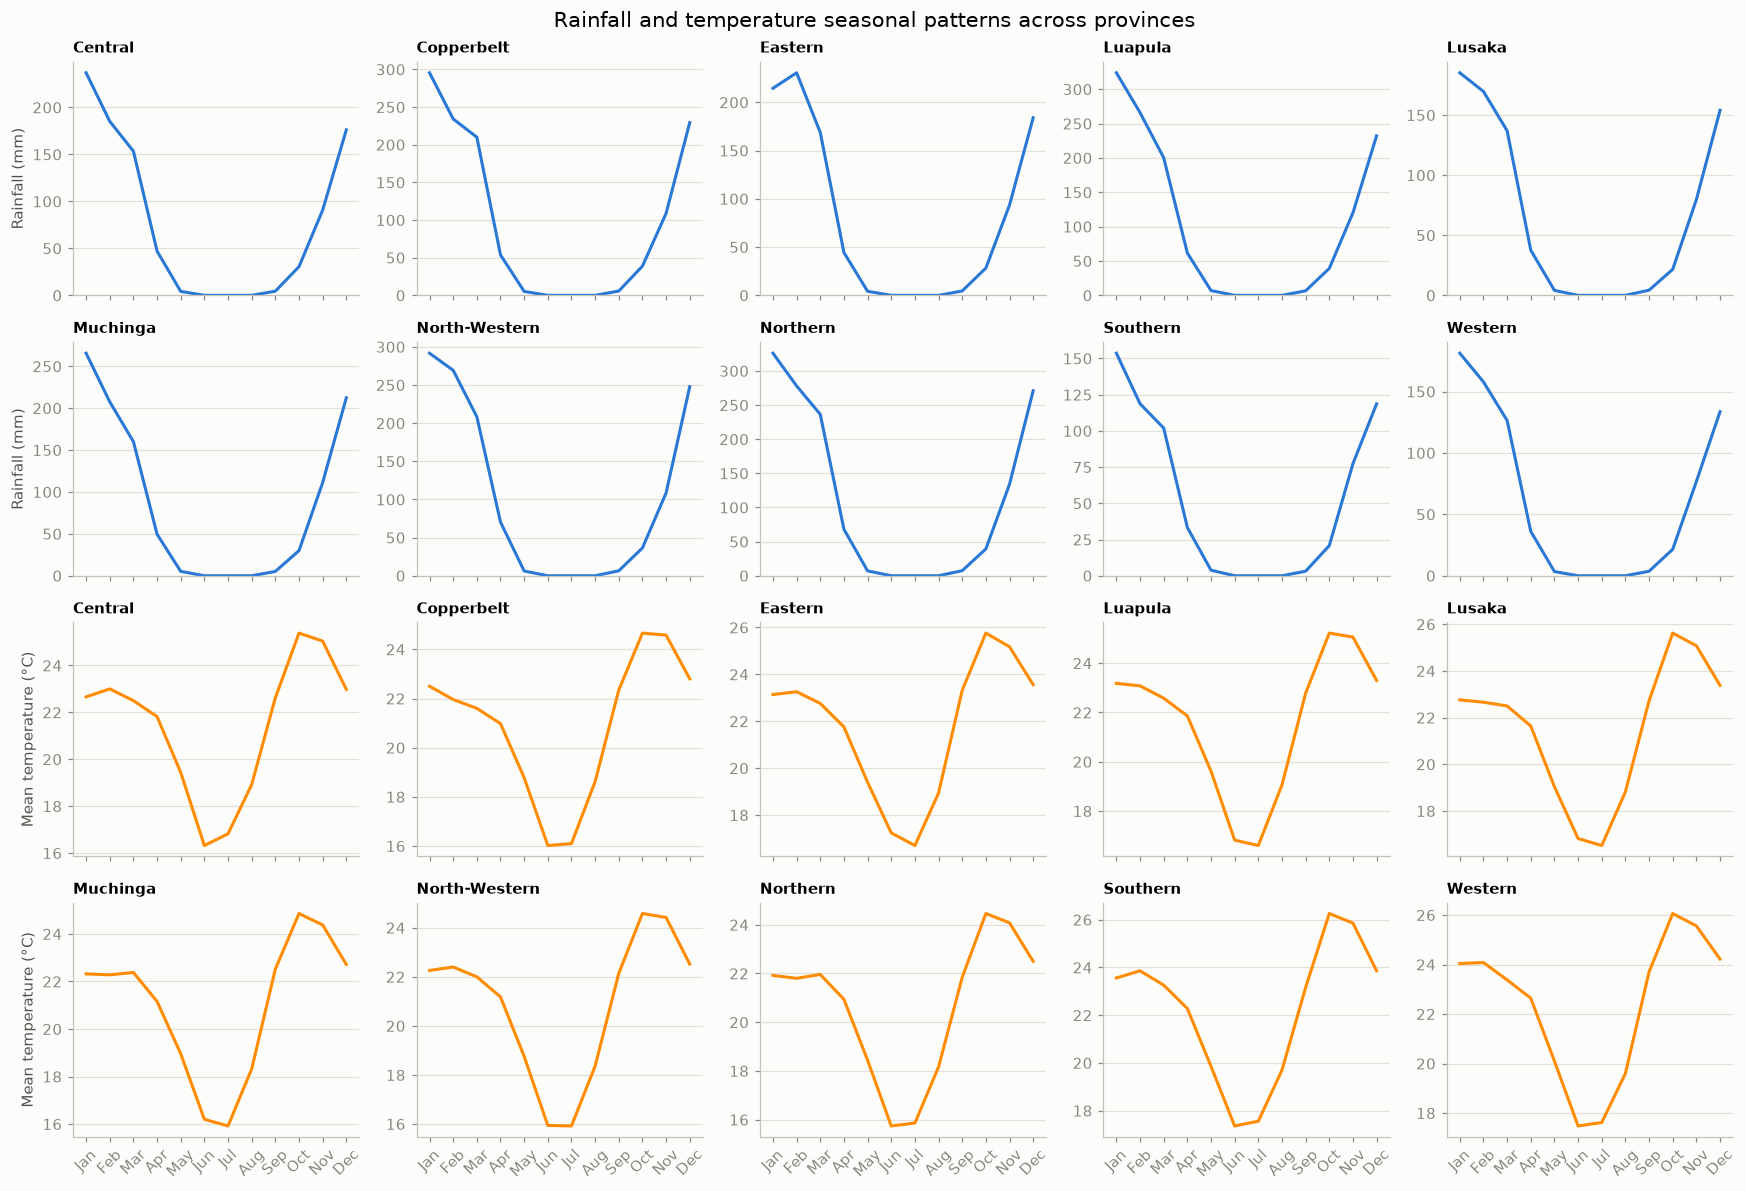

In [51]:
# Critique redesign:
# Small multiples with rainfall and temperature separated

import matplotlib.pyplot as plt

# Calculate seasonal monthly averages
seasonal = (
    monthly
    .groupby(["province", "month"], as_index=False)
    [["rainfall_mm", "temp_mean_c"]]
    .mean()
)

provinces = sorted(seasonal["province"].unique())

month_names = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

# 4 rows × 5 columns:
# top 2 rows = rainfall
# bottom 2 rows = temperature
fig, axes = plt.subplots(
    4,
    5,
    figsize=(16, 11),
    sharex=True
)

# Rainfall small multiples
for ax, province in zip(axes[:2].flatten(), provinces):

    sub = seasonal[seasonal["province"] == province]

    ax.plot(
        sub["month"],
        sub["rainfall_mm"],
        color=BLUE,
        linewidth=2
    )

    ax.set_title(province, fontsize=10)
    ax.set_ylim(bottom=0)
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(month_names, rotation=45)


# Temperature small multiples
for ax, province in zip(axes[2:].flatten(), provinces):

    sub = seasonal[seasonal["province"] == province]

    ax.plot(
        sub["month"],
        sub["temp_mean_c"],
        color="darkorange",
        linewidth=2
    )

    ax.set_title(province, fontsize=10)
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(month_names, rotation=45)


# Add row labels
axes[0, 0].set_ylabel("Rainfall (mm)")
axes[1, 0].set_ylabel("Rainfall (mm)")
axes[2, 0].set_ylabel("Mean temperature (°C)")
axes[3, 0].set_ylabel("Mean temperature (°C)")

fig.suptitle(
    "Rainfall and temperature seasonal patterns across provinces",
    fontsize=14
)

plt.tight_layout()
plt.show()

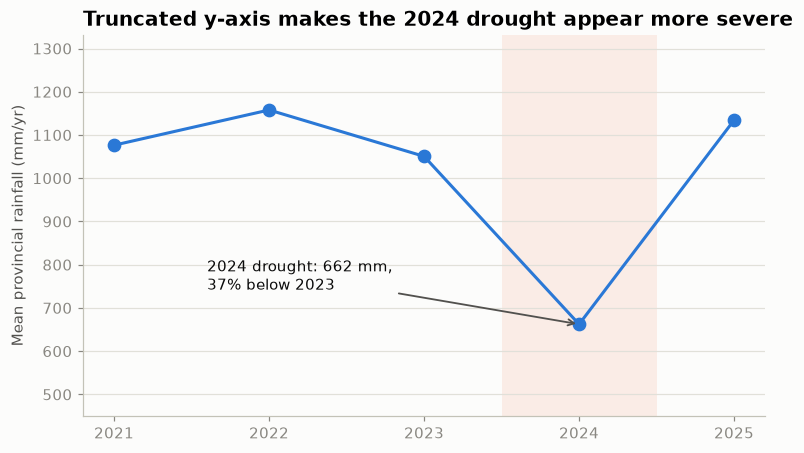

In [52]:
# Honesty: Step 23 with y-axis starting at 450 mm

import matplotlib.pyplot as plt

# Calculate national mean annual rainfall
national = annual.groupby("year")["total_rainfall_mm"].mean()

fig, ax = plt.subplots(figsize=(8, 4.5))

# Plot annual rainfall
ax.plot(
    national.index,
    national.values,
    color=BLUE,
    marker="o",
    markersize=8
)

# Highlight 2024 drought
ax.axvspan(
    2023.5,
    2024.5,
    color=ORANGE,
    alpha=0.10,
    linewidth=0
)

# Annotate the drought
ax.annotate(
    f"2024 drought: {national[2024]:.0f} mm,\n"
    f"{(1 - national[2024] / national[2023]) * 100:.0f}% below 2023",
    xy=(2024, national[2024]),
    xytext=(2021.6, national[2024] + 80),
    arrowprops=dict(
        arrowstyle="->",
        color=INK_SOFT,
        linewidth=1.2
    ),
    fontsize=10,
    color=INK
)

ax.set_xticks(national.index)

# IMPORTANT: truncated y-axis starts at 450 mm
ax.set_ylim(450, national.max() * 1.15)

ax.set_ylabel("Mean provincial rainfall (mm/yr)")
ax.set_title("Truncated y-axis makes the 2024 drought appear more severe")

plt.show()

Starting the y-axis at 450 mm makes the 2024 drought appear much more severe because the difference between 2023 and 2024 occupies a larger proportion of the plotting area. However, the underlying data have not changed: mean provincial rainfall fell from approximately 1,051 mm in 2023 to 662 mm in 2024, a decline of about 37%. A non-zero starting point can be acceptable when the purpose is to reveal small variations and zero is not an important reference point, provided the truncated scale is clearly shown. It is inappropriate when truncation exaggerates differences and may mislead the reader about their true magnitude.